### Mount Brown South accumulation record: correction for strain thinning using ApRES derived vertical strain rate, and comparison to Nye 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from scipy.ndimage import gaussian_filter1d


In [2]:
# import chronology csv, with IE layer thickness column
composite_accum = pd.read_csv("data/mbs_composite_chronology_IE.csv")
composite_accum

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness,fitted_densities,IE_layer_thickness,IE_depth
0,0.588,1,2017,0.2940,0.588,443.839763,0.284600,0.141457
1,1.044,1,2016,0.8160,0.456,452.858835,0.225195,0.396700
2,1.717,1,2015,1.3805,0.673,462.125156,0.339161,0.678355
3,2.024,1,2014,1.8705,0.307,469.783619,0.157278,0.927353
4,2.444,1,2013,2.2340,0.420,475.246751,0.217670,1.114665
...,...,...,...,...,...,...,...,...
1140,293.732,1,877,293.5410,0.382,916.899546,0.381958,271.609468
1141,294.013,1,876,293.8725,0.281,916.900567,0.280970,271.940932
1142,294.319,1,875,294.1660,0.306,916.901462,0.305967,272.234400
1143,294.501,1,874,294.4100,0.182,916.902200,0.181981,272.478374


In [3]:
def nye(d, l, H):
    """Function that calculates original layer thickness as a function of depth
     l/L = h/H
    L : original accumulation IE
    l : observed layer thickness IE
    H : height of ice sheet IE
    h : height above bed
    d : IE depth
    h = H - d 
    parameters: 
    d : depth IE (array)
    l : current thickness IE (array)
    H : ice sheet height IE (float)"""

    h = H - d

    L = l*H/h

    return L

In [4]:
def strain_thinning(time, current_thickness, strain_rate):
    """Function that calculates initial layer thickness as a function of time, from eq 15.3 and 15.7 in C+P
    parameters: 
    time (years before drilling) (array)
    current_thickness (array)
    strain_rate (float)
    """

    initial_thickness = current_thickness*np.exp(-strain_rate*time)

    return initial_thickness

In [5]:
strain_thinning(1000, 1, -2.6*10**-4)

1.2969300866657718

In [6]:
# make an age column
composite_accum["age"] = 2017 - composite_accum["Year"]
composite_accum

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness,fitted_densities,IE_layer_thickness,IE_depth,age
0,0.588,1,2017,0.2940,0.588,443.839763,0.284600,0.141457,0
1,1.044,1,2016,0.8160,0.456,452.858835,0.225195,0.396700,1
2,1.717,1,2015,1.3805,0.673,462.125156,0.339161,0.678355,2
3,2.024,1,2014,1.8705,0.307,469.783619,0.157278,0.927353,3
4,2.444,1,2013,2.2340,0.420,475.246751,0.217670,1.114665,4
...,...,...,...,...,...,...,...,...,...
1140,293.732,1,877,293.5410,0.382,916.899546,0.381958,271.609468,1140
1141,294.013,1,876,293.8725,0.281,916.900567,0.280970,271.940932,1141
1142,294.319,1,875,294.1660,0.306,916.901462,0.305967,272.234400,1142
1143,294.501,1,874,294.4100,0.182,916.902200,0.181981,272.478374,1143


In [7]:
# make new column of IE accum calculated using nye model
# 1978 is ice equivalent ice sheet height

composite_accum["IE_accum_nye_1978"] =nye(composite_accum["IE_depth"], composite_accum["IE_layer_thickness"], 1978)
composite_accum

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness,fitted_densities,IE_layer_thickness,IE_depth,age,IE_accum_nye_1978
0,0.588,1,2017,0.2940,0.588,443.839763,0.284600,0.141457,0,0.284620
1,1.044,1,2016,0.8160,0.456,452.858835,0.225195,0.396700,1,0.225240
2,1.717,1,2015,1.3805,0.673,462.125156,0.339161,0.678355,2,0.339277
3,2.024,1,2014,1.8705,0.307,469.783619,0.157278,0.927353,3,0.157351
4,2.444,1,2013,2.2340,0.420,475.246751,0.217670,1.114665,4,0.217793
...,...,...,...,...,...,...,...,...,...,...
1140,293.732,1,877,293.5410,0.382,916.899546,0.381958,271.609468,1140,0.442755
1141,294.013,1,876,293.8725,0.281,916.900567,0.280970,271.940932,1141,0.325755
1142,294.319,1,875,294.1660,0.306,916.901462,0.305967,272.234400,1142,0.354798
1143,294.501,1,874,294.4100,0.182,916.902200,0.181981,272.478374,1143,0.211054


In [8]:
# make new column of IE accum calculated using strain rate from ApRES
composite_accum["IE_accum_SR2.59"] = strain_thinning(composite_accum["age"], composite_accum["IE_layer_thickness"], -2.59*10**-4)
composite_accum

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness,fitted_densities,IE_layer_thickness,IE_depth,age,IE_accum_nye_1978,IE_accum_SR2.59
0,0.588,1,2017,0.2940,0.588,443.839763,0.284600,0.141457,0,0.284620,0.284600
1,1.044,1,2016,0.8160,0.456,452.858835,0.225195,0.396700,1,0.225240,0.225253
2,1.717,1,2015,1.3805,0.673,462.125156,0.339161,0.678355,2,0.339277,0.339336
3,2.024,1,2014,1.8705,0.307,469.783619,0.157278,0.927353,3,0.157351,0.157400
4,2.444,1,2013,2.2340,0.420,475.246751,0.217670,1.114665,4,0.217793,0.217896
...,...,...,...,...,...,...,...,...,...,...,...
1140,293.732,1,877,293.5410,0.382,916.899546,0.381958,271.609468,1140,0.442755,0.513151
1141,294.013,1,876,293.8725,0.281,916.900567,0.280970,271.940932,1141,0.325755,0.377573
1142,294.319,1,875,294.1660,0.306,916.901462,0.305967,272.234400,1142,0.354798,0.411272
1143,294.501,1,874,294.4100,0.182,916.902200,0.181981,272.478374,1143,0.211054,0.244677


In [10]:
# upper and lower bounds of apRES strain rate, −2.59 × 10−4 ± 1.5 × 10−5 year−1 
-2.59*10**-4 + 1.5*10**-5, -2.59*10**-4 - 1.5*10**-5

(-0.000244, -0.000274)

In [11]:
composite_accum["IE_accum_SR2.44"] = strain_thinning(composite_accum["age"], composite_accum["IE_layer_thickness"], -2.44*10**-4)
composite_accum["IE_accum_SR2.74"] = strain_thinning(composite_accum["age"], composite_accum["IE_layer_thickness"], -2.74*10**-4)
composite_accum

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness,fitted_densities,IE_layer_thickness,IE_depth,age,IE_accum_nye_1978,IE_accum_SR2.59,IE_accum_SR2.44,IE_accum_SR2.74
0,0.588,1,2017,0.2940,0.588,443.839763,0.284600,0.141457,0,0.284620,0.284600,0.284600,0.284600
1,1.044,1,2016,0.8160,0.456,452.858835,0.225195,0.396700,1,0.225240,0.225253,0.225250,0.225257
2,1.717,1,2015,1.3805,0.673,462.125156,0.339161,0.678355,2,0.339277,0.339336,0.339326,0.339346
3,2.024,1,2014,1.8705,0.307,469.783619,0.157278,0.927353,3,0.157351,0.157400,0.157393,0.157407
4,2.444,1,2013,2.2340,0.420,475.246751,0.217670,1.114665,4,0.217793,0.217896,0.217883,0.217909
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1140,293.732,1,877,293.5410,0.382,916.899546,0.381958,271.609468,1140,0.442755,0.513151,0.504451,0.522002
1141,294.013,1,876,293.8725,0.281,916.900567,0.280970,271.940932,1141,0.325755,0.377573,0.371166,0.384091
1142,294.319,1,875,294.1660,0.306,916.901462,0.305967,272.234400,1142,0.354798,0.411272,0.404287,0.418378
1143,294.501,1,874,294.4100,0.182,916.902200,0.181981,272.478374,1143,0.211054,0.244677,0.240517,0.248908


In [21]:
def get_change(current, previous):
    return (abs(current - previous) / ((current + previous)/2)) *100


In [26]:
get_change(0.338393,0.350208
)

3.4315953650953217

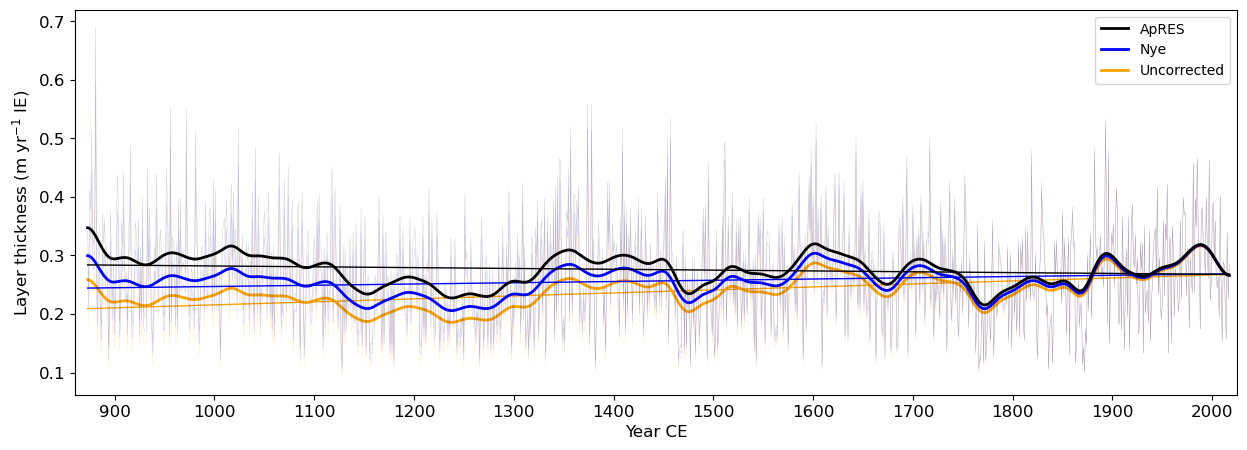

In [15]:
# plot to compare layer thinning methods
timestamp = datetime.now().strftime('%Y%m%d_%H%M')


nye_colour = "blue"
apres_colour="black"
raw_colour = "orange"
alpha_ = 0.2
lw_ = 0.3

# Calculate the best-fit line for raw
z_raw = np.polyfit(composite_accum["Year"], composite_accum["IE_layer_thickness"], 1)
p_raw = np.poly1d(z_raw
                 )


# Calculate the best-fit line for nye
z_nye = np.polyfit(composite_accum["Year"], composite_accum["IE_accum_nye_1978"], 1)
p_nye = np.poly1d(z_nye)

# Calculate the best-fit line for apres strain rate
z_apres = np.polyfit(composite_accum["Year"], composite_accum["IE_accum_SR2.59"], 1)
p_apres = np.poly1d(z_apres)

fig, ax = plt.subplots(figsize=(15,5))

sigma_value =10


gfilter = gaussian_filter1d(composite_accum["IE_layer_thickness"], sigma=sigma_value)
# ax.axhline(y=np.mean(composite_accum["IE_layer_thickness"]), color = raw_colour, linewidth=1, linestyle='--')
ax.plot(composite_accum["Year"], composite_accum["IE_layer_thickness"],  color= raw_colour, alpha=alpha_, linewidth=lw_)
ax.plot(composite_accum["Year"], gfilter, color= raw_colour, alpha=1, linewidth=2, label = "Uncorrected",)
ax.plot(composite_accum["Year"], p_raw(composite_accum["Year"]), color=raw_colour, linewidth=1)

gfilter = gaussian_filter1d(composite_accum["IE_accum_nye_1978"], sigma=sigma_value)
# ax.axhline(y=np.mean(composite_accum["IE_accum_nye_1978"]), color = nye_colour, linewidth=1, linestyle='--')
ax.plot(composite_accum["Year"], composite_accum["IE_accum_nye_1978"],  color= nye_colour, alpha=alpha_, linewidth=lw_)
ax.plot(composite_accum["Year"], gfilter, color= nye_colour, alpha=1, linewidth=2, label = "Nye",)
ax.plot(composite_accum["Year"], p_nye(composite_accum["Year"]), color=nye_colour, linewidth=1)


gfilter = gaussian_filter1d(composite_accum["IE_accum_SR2.59"], sigma=sigma_value)
# ax.axhline(y=np.mean(composite_accum["IE_accum_SR2.59"]), color = apres_colour, linewidth=1, linestyle='--')
ax.plot(composite_accum["Year"], composite_accum["IE_accum_SR2.59"],  color= apres_colour, alpha=alpha_, linewidth=lw_)
ax.plot(composite_accum["Year"], gfilter, color= apres_colour, alpha=1, linewidth=2, label = "ApRES")
ax.plot(composite_accum["Year"], p_apres(composite_accum["Year"]), color=apres_colour,  linewidth=1)

ax.set_xlabel('Year CE', size=12)
ax.set_ylabel('Layer thickness (m yr$^{-1}$ IE)', size=12)
ax.set_xticks(ticks=np.arange(800, 2100, 100.0))
ax.tick_params(axis='both', which='major', labelsize=12)
ax.set_title("")
ax.set_xlim(860, 2025)
ax.legend(reverse=True)

In [16]:
composite_accum["IE_accum_apres"] = composite_accum["IE_accum_SR2.59"]

In [17]:
# save to csv
composite_accum.to_csv("data/mbs_accum_record.csv", index=False)